# Module 07 — Probability Foundations

This notebook is the runnable companion to the concept guide: read [README.md](README.md) first,
or keep it open alongside. Every section below mirrors a numbered section of the guide. We simulate
dice and coins to watch frequencies settle on probabilities, work through the two-stage manufacturing
tree and the diagnostic-test example (including a plot of PPV against prevalence), simulate Monty Hall,
draw PMFs, PDFs and CDFs, check linearity of expectation on *dependent* variables, test Chebyshev's
inequality, estimate $\pi$ by Monte Carlo and watch the error fall like $1/\sqrt{n}$, check the birthday
problem by simulation, and finally build a naive Bayes spam filter by hand and verify it against scikit-learn.

Everything is plain NumPy first; library calls appear only afterwards, to confirm the hand computation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)

## 1. Frequencies settle on probabilities

The frequentist reading of $P(\text{heads}) = 0.5$ is a statement about the long run: the proportion of
heads in $n$ flips approaches $0.5$ as $n$ grows. Section 8 of the guide tells us *how fast*: the
proportion of successes in $n$ trials has standard deviation $\sqrt{p(1-p)/n} \le \frac{1}{2\sqrt{n}}$,
so we draw that band around the true value.

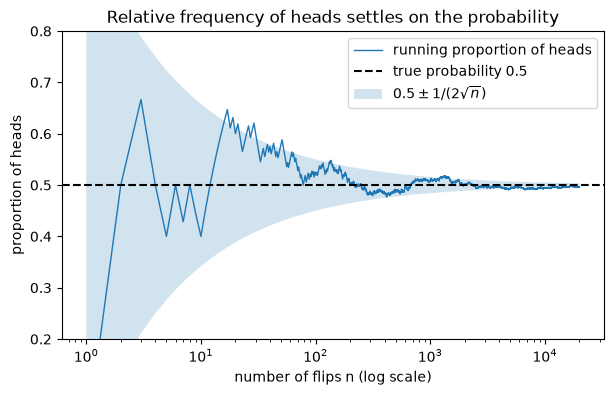

after     10 flips: proportion of heads = 0.4000   (band half-width 1/(2 sqrt n) = 0.1581)
after    100 flips: proportion of heads = 0.5200   (band half-width 1/(2 sqrt n) = 0.0500)
after   1000 flips: proportion of heads = 0.5090   (band half-width 1/(2 sqrt n) = 0.0158)
after  10000 flips: proportion of heads = 0.4939   (band half-width 1/(2 sqrt n) = 0.0050)
after  20000 flips: proportion of heads = 0.4964   (band half-width 1/(2 sqrt n) = 0.0035)


In [2]:
n_flips = 20_000
flips = rng.integers(0, 2, size=n_flips)                 # 1 = heads
n = np.arange(1, n_flips + 1)
running_freq = np.cumsum(flips) / n

plt.plot(n, running_freq, lw=1, label="running proportion of heads")
plt.axhline(0.5, color="k", ls="--", label="true probability 0.5")
plt.fill_between(n, 0.5 - 1/(2*np.sqrt(n)), 0.5 + 1/(2*np.sqrt(n)), alpha=0.2,
                 label=r"$0.5 \pm 1/(2\sqrt{n})$")
plt.xscale("log"); plt.ylim(0.2, 0.8)
plt.xlabel("number of flips n (log scale)"); plt.ylabel("proportion of heads")
plt.title("Relative frequency of heads settles on the probability")
plt.legend(loc="upper right"); plt.show()

for k in (10, 100, 1_000, 10_000, 20_000):
    print(f"after {k:>6d} flips: proportion of heads = {running_freq[k-1]:.4f}   "
          f"(band half-width 1/(2 sqrt n) = {1/(2*np.sqrt(k)):.4f})")

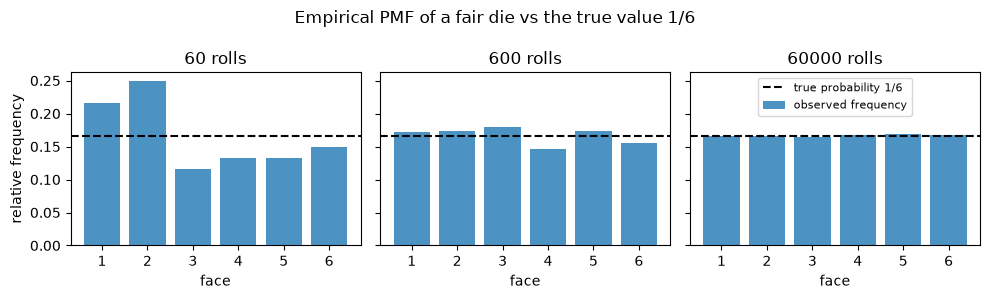

In [3]:
faces = np.arange(1, 7)
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, n_rolls in zip(axes, (60, 600, 60_000)):
    rolls = rng.integers(1, 7, size=n_rolls)
    freq = np.array([(rolls == f).mean() for f in faces])
    ax.bar(faces, freq, alpha=0.8, label="observed frequency")
    ax.axhline(1/6, color="k", ls="--", label="true probability 1/6")
    ax.set_xticks(faces)
    ax.set_title(f"{n_rolls} rolls"); ax.set_xlabel("face")
axes[0].set_ylabel("relative frequency")
axes[2].legend(fontsize=8, loc="upper center")       # the 60,000-roll panel has room above its bars
fig.suptitle("Empirical PMF of a fair die vs the true value 1/6")
plt.tight_layout(); plt.show()

Notice that the running proportion wanders a lot for the first few hundred flips and then hugs $0.5$
ever more tightly — but the band narrows only like $1/\sqrt{n}$: going from 100 to 10,000 flips
(100 times the work) shrinks the typical error by a factor of 10, from about $0.05$ to about $0.005$.
With the die, 60 rolls give a lumpy histogram, 600 a recognisable one, 60,000 a nearly flat one.

## 2. Sample spaces, events and the axioms — two dice by brute force

With equally likely outcomes, probability *is* counting: $P(A) = |A| / |\Omega|$. We enumerate all 36
outcomes of two dice as a Python set, define events as subsets, and check the rules of Section 2 of
the guide — complement, disjoint additivity, inclusion–exclusion and the union bound — numerically.

In [4]:
from itertools import product

omega = [(i, j) for i, j in product(range(1, 7), repeat=2)]
N = len(omega)

def prob(event):                        # equally likely outcomes: probability = |A| / |Omega|
    return len(event) / N

A = {w for w in omega if sum(w) == 7}          # sum is 7
B = {w for w in omega if w[0] == w[1]}         # doubles
C = {w for w in omega if 6 in w}               # at least one six

print(f"|Omega| = {N}")
print(f"P(A: sum = 7)          = {len(A)}/36 = {prob(A):.4f}")
print(f"P(B: doubles)          = {len(B)}/36 = {prob(B):.4f}")
print(f"P(C: at least one six) = {len(C)}/36 = {prob(C):.4f}   complement rule: 1 - 25/36 = {1 - 25/36:.4f}")
print()
print(f"A and B disjoint? {len(A & B) == 0}  ->  P(A u B) = {prob(A | B):.4f}  =  P(A) + P(B) = {prob(A) + prob(B):.4f}")
print(f"A and C overlap:  P(A n C) = {prob(A & C):.4f}")
print(f"inclusion-exclusion: P(A u C) = {prob(A | C):.4f}  =  P(A) + P(C) - P(A n C) = {prob(A) + prob(C) - prob(A & C):.4f}")
print(f"union bound:         P(A u C) = {prob(A | C):.4f} <= P(A) + P(C) = {prob(A) + prob(C):.4f}")
print()
print(f"cards: P(ace or heart) = 4/52 + 13/52 - 1/52 = {(4 + 13 - 1)/52:.4f}")
print(f"cards: P(two aces in a two-card hand) = C(4,2)/C(52,2) = {comb(4, 2)}/{comb(52, 2)} = {comb(4, 2)/comb(52, 2):.5f} = 1/221")

|Omega| = 36
P(A: sum = 7)          = 6/36 = 0.1667
P(B: doubles)          = 6/36 = 0.1667
P(C: at least one six) = 11/36 = 0.3056   complement rule: 1 - 25/36 = 0.3056

A and B disjoint? True  ->  P(A u B) = 0.3333  =  P(A) + P(B) = 0.3333
A and C overlap:  P(A n C) = 0.0556
inclusion-exclusion: P(A u C) = 0.4167  =  P(A) + P(C) - P(A n C) = 0.4167
union bound:         P(A u C) = 0.4167 <= P(A) + P(C) = 0.4722

cards: P(ace or heart) = 4/52 + 13/52 - 1/52 = 0.3077
cards: P(two aces in a two-card hand) = C(4,2)/C(52,2) = 6/1326 = 0.00452 = 1/221


The intersection term in inclusion–exclusion is exactly what stops you from double-counting
$(1, 6)$ and $(6, 1)$, which belong to both "sum is 7" and "at least one six". The union bound
gives up that correction and is therefore loose — but it never needs to know how the events overlap.

**Try it yourself:** define the event "the sum is at least 10" and the event "the two faces differ
by exactly 1"; compute $P$ of each, of their intersection and of their union, and confirm
inclusion–exclusion by counting.

## 3. Conditional probability, total probability and (non-)independence

The two-stage manufacturing example from the guide: $P(D_1) = 0.04$, $P(D_2 \mid D_1) = 0.10$,
$P(D_2 \mid D_1^c) = 0.02$. We compute the four leaves of the probability tree with the
multiplication rule, get $P(D_2)$ from the law of total probability, invert with
$P(D_1 \mid D_2) = P(D_1 \cap D_2) / P(D_2)$, and then simulate 200,000 parts to confirm.

In [5]:
p_d1 = 0.04
p_d2_given_d1, p_d2_given_not_d1 = 0.10, 0.02

leaves = {
    "D1 and D2":         p_d1 * p_d2_given_d1,
    "D1 and not D2":     p_d1 * (1 - p_d2_given_d1),
    "not D1 and D2":     (1 - p_d1) * p_d2_given_not_d1,
    "not D1 and not D2": (1 - p_d1) * (1 - p_d2_given_not_d1),
}
for name, p in leaves.items():
    print(f"P({name:17s}) = {p:.4f}")
print(f"sum of the four leaves = {sum(leaves.values()):.10f}")

p_d2 = leaves["D1 and D2"] + leaves["not D1 and D2"]      # law of total probability
p_defective = 1 - leaves["not D1 and not D2"]              # complement of 'no damage anywhere'
p_d1_given_d2 = leaves["D1 and D2"] / p_d2                 # definition of conditional probability
print(f"\nP(D2) = {p_d2:.4f}    P(defective) = {p_defective:.4f}    P(D1 | D2) = {p_d1_given_d2:.4f}")
print(f"independence test: P(D1) P(D2) = {p_d1 * p_d2:.5f}  vs  P(D1 and D2) = {leaves['D1 and D2']:.5f}  -> dependent")

# simulate the two stages for 200,000 parts
n_parts = 200_000
d1 = rng.random(n_parts) < p_d1
d2 = rng.random(n_parts) < np.where(d1, p_d2_given_d1, p_d2_given_not_d1)
p_hat = d1[d2].mean()                                   # estimated from the d2.sum() parts that have D2 only
se_hat = np.sqrt(p_hat * (1 - p_hat) / d2.sum())
print(f"\nsimulation: P(D2) ~ {d2.mean():.4f}   P(D1 | D2) ~ {p_hat:.4f} +/- {se_hat:.4f} "
      f"(from only {d2.sum()} parts with D2)   P(defective) ~ {(d1 | d2).mean():.4f}")

P(D1 and D2        ) = 0.0040
P(D1 and not D2    ) = 0.0360
P(not D1 and D2    ) = 0.0192
P(not D1 and not D2) = 0.9408
sum of the four leaves = 1.0000000000

P(D2) = 0.0232    P(defective) = 0.0592    P(D1 | D2) = 0.1724
independence test: P(D1) P(D2) = 0.00093  vs  P(D1 and D2) = 0.00400  -> dependent

simulation: P(D2) ~ 0.0231   P(D1 | D2) ~ 0.1844 +/- 0.0057 (from only 4610 parts with D2)   P(defective) ~ 0.0586


Two things to notice. First, the simulation of "conditioning" is literally *filtering*: `d1[d2]`
keeps only the parts for which $D_2$ happened and asks how often $D_1$ holds among them — the new,
smaller sample space. That is also why the simulated $P(D_1 \mid D_2)$ is the noisiest of the three
estimates: it rests on the few thousand parts with $D_2$, not on all 200,000, so its standard error
(printed next to it) is more than ten times those of the other two, and a distance of about two
standard errors from the exact $0.1724$ is ordinary noise. Second, $P(D_1 \mid D_2) \approx 0.17$ is
more than four times $P(D_1) = 0.04$: knowing about stage-2 damage changes what you believe about
stage 1, which is exactly what "dependent" means.

The same tree in natural frequencies: out of 10,000 parts, $40$ are damaged at both stages, $360$ only
at stage 1, $192$ only at stage 2 and $9{,}408$ not at all. The next figure draws every one of them.

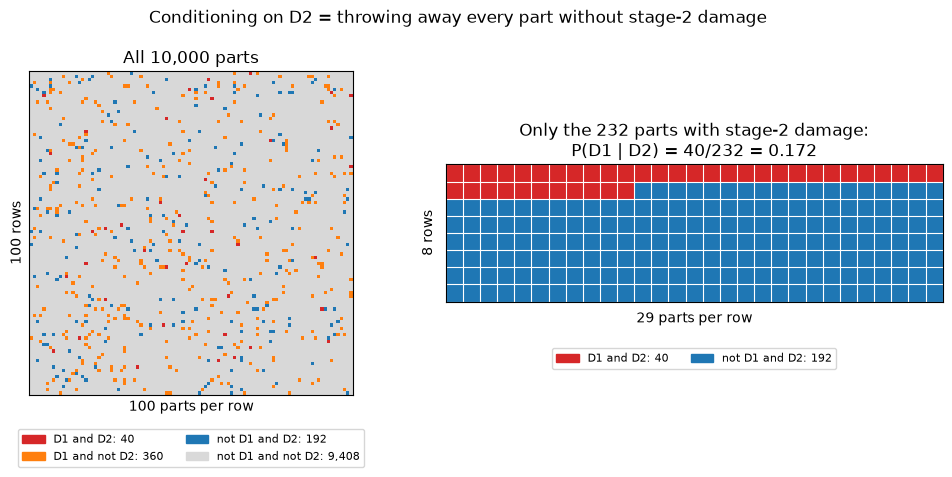

In [6]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

n_grid = 10_000
grid_counts = {k: int(round(v * n_grid)) for k, v in leaves.items()}     # 40, 360, 192, 9408
colours = ["C3", "C1", "C0", "0.85"]
cmap4 = ListedColormap(colours)
codes = np.repeat(np.arange(4), list(grid_counts.values()))
codes = codes[np.random.default_rng(7).permutation(n_grid)].reshape(100, 100)   # shuffle positions only
n_d2 = grid_counts["D1 and D2"] + grid_counts["not D1 and D2"]                   # 232 parts with D2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
ax1.imshow(codes, cmap=cmap4, vmin=-0.5, vmax=3.5, interpolation="nearest")
ax1.set_xticks([]); ax1.set_yticks([])
ax1.set_xlabel("100 parts per row"); ax1.set_ylabel("100 rows")
ax1.set_title("All 10,000 parts")
ax1.legend(handles=[Patch(color=c, label=f"{k}: {v:,}") for (k, v), c in zip(grid_counts.items(), colours)],
           loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2, fontsize=8)

sub = np.r_[np.zeros(grid_counts["D1 and D2"]), np.full(grid_counts["not D1 and D2"], 2)].reshape(8, 29)
ax2.imshow(sub, cmap=cmap4, vmin=-0.5, vmax=3.5, interpolation="nearest")
ax2.set_xticks(np.arange(-0.5, 29), minor=True); ax2.set_yticks(np.arange(-0.5, 8), minor=True)
ax2.grid(which="minor", color="white", lw=0.8); ax2.tick_params(which="both", length=0)
ax2.set_xticks([]); ax2.set_yticks([])
ax2.set_xlabel("29 parts per row"); ax2.set_ylabel("8 rows")
ax2.set_title(f"Only the {n_d2} parts with stage-2 damage:\n"
              f"P(D1 | D2) = {grid_counts['D1 and D2']}/{n_d2} = {grid_counts['D1 and D2'] / n_d2:.3f}")
ax2.legend(handles=[Patch(color=colours[0], label=f"D1 and D2: {grid_counts['D1 and D2']}"),
                    Patch(color=colours[2], label=f"not D1 and D2: {grid_counts['not D1 and D2']}")],
           loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2, fontsize=8)
fig.suptitle("Conditioning on D2 = throwing away every part without stage-2 damage")
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

**Notice that** the 40 red parts are almost invisible among all 10,000 — that is $P(D_1 \cap D_2) = 0.004$ —
but in the right panel, where the 9,768 parts without stage-2 damage have been thrown away, they fill
$40/232 = 17\%$ of the picture. Conditioning does not change any count; it changes the denominator. The
orange parts (damaged at stage 1 only) disappear entirely, because they do not belong to the new sample space.

## 4. Bayes' theorem — the diagnostic test

Sensitivity $P(+ \mid D) = 0.99$, specificity $P(- \mid D^c) = 0.95$, prevalence $P(D) = 0.01$.
Bayes' theorem gives

$$P(D \mid +) = \frac{P(+ \mid D)\,P(D)}{P(+ \mid D)\,P(D) + P(+ \mid D^c)\,P(D^c)} .$$

We write the formula as a function, build the 10,000-person natural-frequency table, and redo the
calculation in odds form — prior odds $\times$ likelihood ratio — including a second, conditionally
independent positive test.

In [7]:
import pandas as pd

def ppv(se, sp, prev):
    # positive predictive value P(D | +): true positives over all positives
    tp = se * prev
    fp = (1 - sp) * (1 - prev)
    return tp / (tp + fp)

def npv(se, sp, prev):
    # negative predictive value P(not D | -)
    tn = sp * (1 - prev)
    fn = (1 - se) * prev
    return tn / (tn + fn)

se, sp, prev = 0.99, 0.95, 0.01
pop = 10_000
table = pd.DataFrame({"test +": [se * prev * pop, (1 - sp) * (1 - prev) * pop],
                      "test -": [(1 - se) * prev * pop, sp * (1 - prev) * pop]},
                     index=["diseased", "healthy"]).round(0).astype(int)
table.loc["total"] = table.sum()
table["total"] = table.sum(axis=1)
print("natural-frequency table for 10,000 people:")
print(table)

print(f"\nPPV = P(D | +)     = {ppv(se, sp, prev):.4f}   (= 99 / 594 = 1/6)")
print(f"NPV = P(not D | -) = {npv(se, sp, prev):.5f}")

prior_odds = prev / (1 - prev)
lr_pos = se / (1 - sp)                     # likelihood ratio of a positive result
post_odds = prior_odds * lr_pos
print(f"\nodds form: prior odds {prior_odds:.4f} x LR+ {lr_pos:.1f} = posterior odds {post_odds:.3f} "
      f"-> probability {post_odds / (1 + post_odds):.4f}")
post_odds_2 = post_odds * lr_pos           # sequential update with a second independent positive test
print(f"after a second positive test: odds {post_odds_2:.3f} -> probability {post_odds_2 / (1 + post_odds_2):.4f}")
print(f"prevalence at which PPV reaches 50%: (1 - sp) / (se + 1 - sp) = {(1 - sp) / (se + 1 - sp):.4f}")

natural-frequency table for 10,000 people:
          test +  test -  total
diseased      99       1    100
healthy      495    9405   9900
total        594    9406  10000

PPV = P(D | +)     = 0.1667   (= 99 / 594 = 1/6)
NPV = P(not D | -) = 0.99989

odds form: prior odds 0.0101 x LR+ 19.8 = posterior odds 0.200 -> probability 0.1667
after a second positive test: odds 3.960 -> probability 0.7984
prevalence at which PPV reaches 50%: (1 - sp) / (se + 1 - sp) = 0.0481


The odds form makes sequential evidence simple: every further conditionally independent positive
result multiplies the odds by the same $\text{LR}^+ = 19.8$, and a negative result multiplies them by
$\text{LR}^- = (1 - \text{se})/\text{sp} = 0.01/0.95$. Taking logarithms turns the products into sums,
so we plot the posterior both ways.

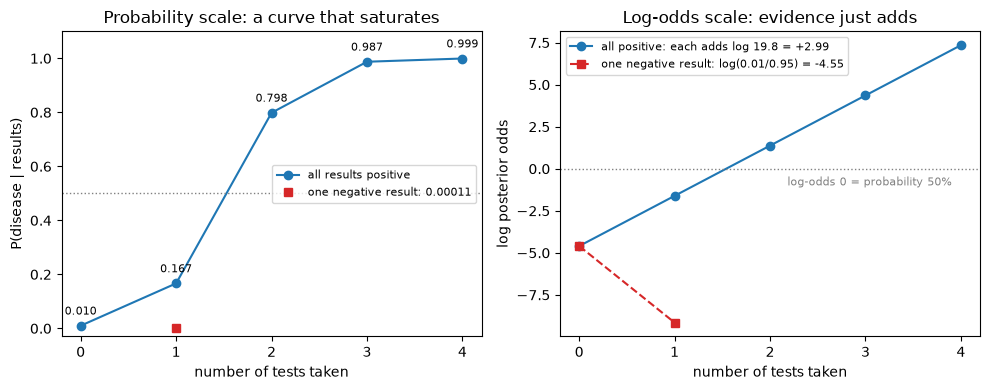

In [8]:
lr_neg = (1 - se) / sp                                   # likelihood ratio of a negative result
n_tests = np.arange(0, 5)                                # number of positive results so far
log_odds = np.log(prior_odds) + n_tests * np.log(lr_pos)
post_prob = 1 / (1 + np.exp(-log_odds))
lo_neg = np.log(prior_odds) + np.log(lr_neg)             # one negative result instead
p_neg = 1 / (1 + np.exp(-lo_neg))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(n_tests, post_prob, "o-", label="all results positive")
ax1.plot(1, p_neg, "s", color="C3", label=f"one negative result: {p_neg:.5f}")
for kk, p in zip(n_tests, post_prob):
    ax1.annotate(f"{p:.3f}", (kk, p), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax1.axhline(0.5, color="gray", ls=":", lw=1)
ax1.set_ylim(-0.03, 1.1); ax1.set_xticks(n_tests)
ax1.set_xlabel("number of tests taken"); ax1.set_ylabel("P(disease | results)")
ax1.set_title("Probability scale: a curve that saturates"); ax1.legend(fontsize=8, loc="center right")

ax2.plot(n_tests, log_odds, "o-", label=f"all positive: each adds log {lr_pos:.1f} = {np.log(lr_pos):+.2f}")
ax2.plot([0, 1], [log_odds[0], lo_neg], "s--", color="C3",
         label=f"one negative result: log({1 - se:.2f}/{sp:.2f}) = {np.log(lr_neg):+.2f}")
ax2.axhline(0, color="gray", ls=":", lw=1)
ax2.annotate("log-odds 0 = probability 50%", (3.9, 0), textcoords="offset points", xytext=(0, -12),
             ha="right", fontsize=8, color="gray")
ax2.set_xticks(n_tests)
ax2.set_xlabel("number of tests taken"); ax2.set_ylabel("log posterior odds")
ax2.set_title("Log-odds scale: evidence just adds"); ax2.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

**Notice that** the same evidence looks completely different on the two scales. In probability the
steps are $1\% \to 16.7\% \to 79.8\% \to 98.7\% \to 99.9\%$ — huge in the middle, tiny at the ends —
while in log-odds every positive result is the identical step $+2.99$ and the points lie on a
straight line. A single negative result is a step of $-4.55$, bigger than any positive one, because
this test almost never misses a case. Adding log-likelihood ratios is exactly how the naive Bayes
classifier of Section 9 combines words.

Next, the PPV of a single positive test as a function of the prevalence, for four tests.

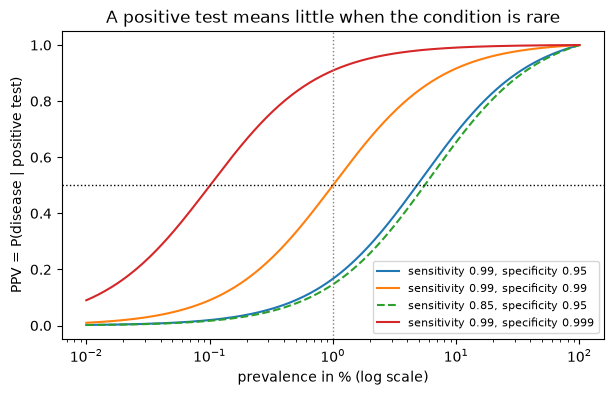

PPV at 1% prevalence: se 0.99/sp 0.95 -> 0.167;  se 0.85/sp 0.95 -> 0.147;  se 0.99/sp 0.99 -> 0.500


In [9]:
prevs = np.logspace(-4, -0.0001, 400)
for s, p_, ls in [(0.99, 0.95, "-"), (0.99, 0.99, "-"), (0.85, 0.95, "--"), (0.99, 0.999, "-")]:
    plt.plot(prevs * 100, ppv(s, p_, prevs), ls, label=f"sensitivity {s}, specificity {p_}")
plt.axhline(0.5, color="k", ls=":", lw=1)
plt.axvline(1, color="gray", ls=":", lw=1)
plt.xscale("log")
plt.xlabel("prevalence in % (log scale)"); plt.ylabel("PPV = P(disease | positive test)")
plt.title("A positive test means little when the condition is rare")
plt.legend(fontsize=8); plt.show()
print(f"PPV at 1% prevalence: se 0.99/sp 0.95 -> {ppv(0.99, 0.95, 0.01):.3f};  se 0.85/sp 0.95 -> {ppv(0.85, 0.95, 0.01):.3f};"
      f"  se 0.99/sp 0.99 -> {ppv(0.99, 0.99, 0.01):.3f}")

At 1% prevalence the 99%/95% test (blue) sits at a PPV of $1/6$; the curve for specificity 0.99
is far higher at every prevalence, while lowering the *sensitivity* from 0.99 to 0.85 at the same
specificity 0.95 (dashed) barely moves it: the PPV at 1% prevalence drops only from 0.167 to 0.147. At
low prevalence the false positives come from the huge healthy population, so specificity is what
counts. Each curve crosses $0.5$ at prevalence $(1 - \text{sp})/(\text{se} + 1 - \text{sp})$.

**Try it yourself:** change the specificity in the first code cell to 0.99 and re-run — how does the
PPV change, and how many false positives remain among 10,000 people?

### Monty Hall by simulation

You pick one of three doors; the host, who knows where the car is, opens a *different* door with a
goat; you may switch to the remaining door. The guide argues that switching wins with probability
$2/3$. Rather than argue, we play the game 50,000 times with the host's behaviour coded explicitly.

In [10]:
def monty_hall(n_games, switch, rng):
    car = rng.integers(0, 3, size=n_games)
    pick = rng.integers(0, 3, size=n_games)
    opened = np.empty(n_games, dtype=int)
    for g in range(n_games):
        # the host opens a door that is neither the pick nor the car (random choice if both qualify)
        options = [d for d in range(3) if d != pick[g] and d != car[g]]
        opened[g] = options[rng.integers(len(options))]
    final = (3 - pick - opened) if switch else pick     # door indices 0 + 1 + 2 = 3
    return (final == car).mean()

n_games = 50_000
p_stay = monty_hall(n_games, switch=False, rng=rng)
p_switch = monty_hall(n_games, switch=True, rng=rng)
se_mc = np.sqrt(p_switch * (1 - p_switch) / n_games)
print(f"P(win | stay)   ~ {p_stay:.4f}")
print(f"P(win | switch) ~ {p_switch:.4f}  +/- {se_mc:.4f}   (exact: 2/3 = {2/3:.4f})")

P(win | stay)   ~ 0.3338
P(win | switch) ~ 0.6674  +/- 0.0021   (exact: 2/3 = 0.6667)


The simulation lands within a couple of standard errors of $2/3$. The reason: your first pick is the
car with probability $1/3$ no matter what the host does afterwards, so the *other* unopened door
carries the remaining $2/3$. The host's opening reveals information only about the door he did not
open — a conditional-probability argument that the simulation makes impossible to dispute.

## 5. Random variables: PMF, CDF, PDF and a change of variables

A random variable is a function from outcomes to numbers. The sum $S$ of two dice maps the 36
outcomes to the integers $2, \dots, 12$; its PMF is $p_S(s) = (6 - |s - 7|)/36$ and its CDF is the
running sum. We compute both exactly from the sample space of Section 2, then draw 20,000 samples
and compare.

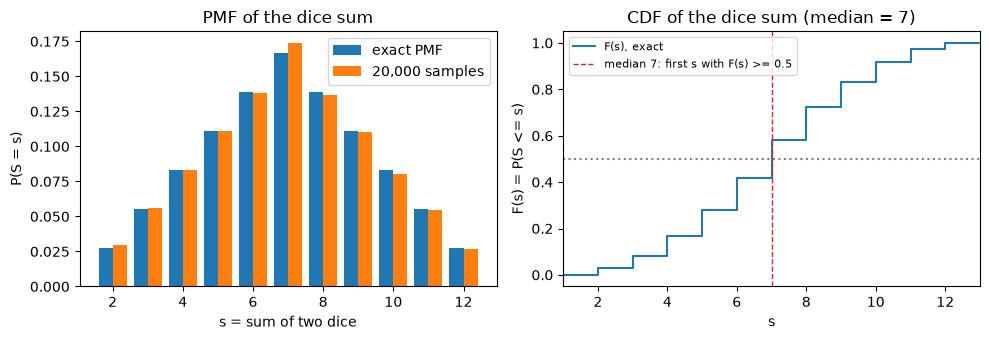

s      :     2     3     4     5     6     7     8     9    10    11    12
PMF*36 :     1     2     3     4     5     6     5     4     3     2     1
CDF    : 0.028 0.083 0.167 0.278 0.417 0.583 0.722 0.833 0.917 0.972 1.000

F(4) = 0.1667 (= 6/36)    median = 7    P(S > 9) = 1 - F(9) = 0.1667


In [11]:
values = np.arange(2, 13)
pmf_exact = np.array([sum(1 for w in omega if sum(w) == s) for s in values]) / N
cdf_exact = np.cumsum(pmf_exact)

samples = rng.integers(1, 7, size=(20_000, 2)).sum(axis=1)
pmf_emp = np.array([(samples == s).mean() for s in values])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.bar(values - 0.2, pmf_exact, width=0.4, label="exact PMF")
ax1.bar(values + 0.2, pmf_emp, width=0.4, label="20,000 samples")
ax1.set_xlabel("s = sum of two dice"); ax1.set_ylabel("P(S = s)"); ax1.set_title("PMF of the dice sum"); ax1.legend()
ax2.step(np.r_[1, values, 13], np.r_[0, cdf_exact, 1], where="post", label="F(s), exact")
ax2.axhline(0.5, color="gray", ls=":")
ax2.axvline(7, color="C3", ls="--", lw=1, label="median 7: first s with F(s) >= 0.5")
ax2.set_xlim(1, 13); ax2.set_xlabel("s"); ax2.set_ylabel("F(s) = P(S <= s)")
ax2.set_title("CDF of the dice sum (median = 7)"); ax2.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

print("s      :", " ".join(f"{s:5d}" for s in values))
print("PMF*36 :", " ".join(f"{int(round(p*36)):5d}" for p in pmf_exact))
print("CDF    :", " ".join(f"{c:5.3f}" for c in cdf_exact))
median = values[np.searchsorted(cdf_exact, 0.5)]        # smallest s with F(s) >= 0.5
print(f"\nF(4) = {cdf_exact[values == 4][0]:.4f} (= 6/36)    median = {median}    P(S > 9) = 1 - F(9) = {1 - cdf_exact[values == 9][0]:.4f}")

### A continuous variable: densities are not probabilities

Let $X \sim \text{Uniform}(0, 1)$ and $Y = X^2$. The change-of-variables formula with
$g^{-1}(y) = \sqrt{y}$ gives $f_Y(y) = \frac{1}{2\sqrt{y}}$ on $(0, 1]$, a density that *exceeds 1*
near 0 and even diverges, yet integrates to 1. The CDF is $F_Y(y) = \sqrt{y}$ and the quantile
function $Q_Y(u) = u^2$, so the median is $0.25$. We check all of this against 100,000 samples.

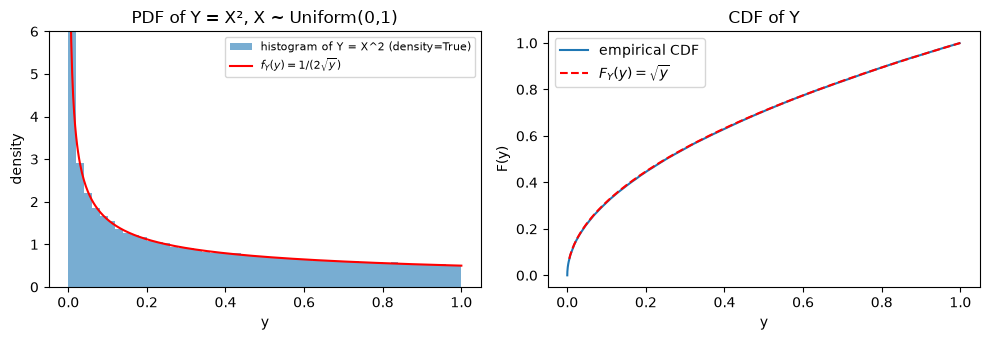

density at y = 0.01: f_Y = 5.0  (> 1, allowed)   but P(Y = 0.01) = 0
P(0 < Y <= 0.01) = integral of f_Y = sqrt(0.01) = 0.100   simulation: 0.0988
median of Y: exact Q(0.5) = 0.5^2 = 0.25   simulation: 0.2514
90th percentile: exact 0.81   simulation: 0.8100
check the density integrates to 1: 1.0000   (midpoint rule; exact: sqrt(1) - sqrt(0) = 1)


In [12]:
x = rng.random(100_000)
y = x ** 2
grid = np.linspace(0.005, 1, 400)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.hist(y, bins=50, density=True, alpha=0.6, label="histogram of Y = X^2 (density=True)")
ax1.plot(grid, 1 / (2 * np.sqrt(grid)), "r", label=r"$f_Y(y) = 1/(2\sqrt{y})$")
ax1.set_ylim(0, 6); ax1.set_xlabel("y"); ax1.set_ylabel("density"); ax1.set_title("PDF of Y = X², X ~ Uniform(0,1)"); ax1.legend(fontsize=8)
ys = np.sort(y); ecdf = np.arange(1, len(ys) + 1) / len(ys)
ax2.plot(ys[::100], ecdf[::100], label="empirical CDF")
ax2.plot(grid, np.sqrt(grid), "r--", label=r"$F_Y(y) = \sqrt{y}$")
ax2.set_xlabel("y"); ax2.set_ylabel("F(y)"); ax2.set_title("CDF of Y"); ax2.legend()
plt.tight_layout(); plt.show()

print(f"density at y = 0.01: f_Y = {1/(2*np.sqrt(0.01)):.1f}  (> 1, allowed)   but P(Y = 0.01) = 0")
print(f"P(0 < Y <= 0.01) = integral of f_Y = sqrt(0.01) = {np.sqrt(0.01):.3f}   simulation: {(y <= 0.01).mean():.4f}")
print(f"median of Y: exact Q(0.5) = 0.5^2 = 0.25   simulation: {np.median(y):.4f}")
print(f"90th percentile: exact 0.81   simulation: {np.quantile(y, 0.9):.4f}")
# midpoint rule on a grid that is fine near y = 0, where the density is infinite (edges u^2, u equally spaced)
edges = np.linspace(0, 1, 200_001) ** 2; mid = 0.5 * (edges[:-1] + edges[1:])
print(f"check the density integrates to 1: {np.sum(np.diff(edges) / (2 * np.sqrt(mid))):.4f}   "
      f"(midpoint rule; exact: sqrt(1) - sqrt(0) = 1)")

Squaring pushes mass towards 0: half of the $Y$ values are below $0.25$. The histogram with
`density=True` is the empirical density; its bars near $y = 0$ rise above 1 just as the formula says.
Keep the three objects apart: the PDF $f_Y$ (a rate), the CDF $F_Y$ (a probability), and the quantile
function $Q_Y = F_Y^{-1}$ (a value) — `np.quantile` computes the last one from samples.

*Why* does the density blow up near 0? Cut the $x$-axis into ten strips of equal probability $0.1$ and
follow each strip through $y = x^2$.

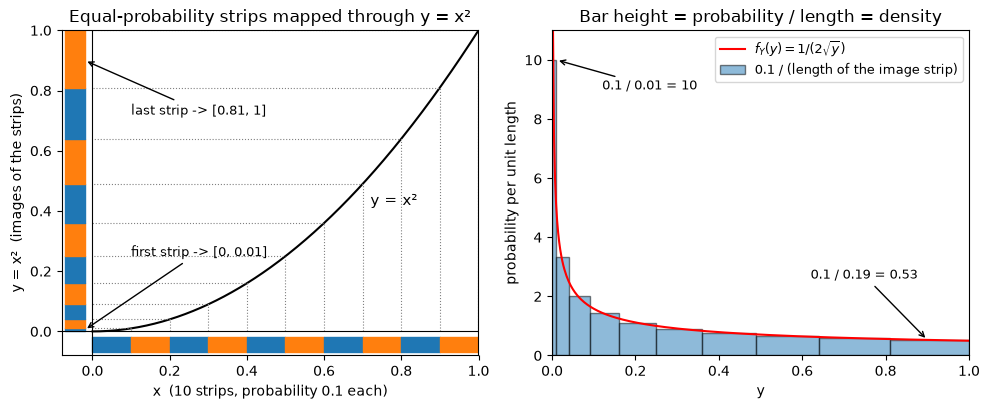

image-strip lengths: [0.01 0.03 0.05 0.07 0.09 0.11 0.13 0.15 0.17 0.19]   bar heights: [10.    3.33  2.    1.43  1.11  0.91  0.77  0.67  0.59  0.53]


In [13]:
cuts = np.linspace(0, 1, 11)                             # 10 strips of x, each with probability 0.1
xx = np.linspace(0, 1, 400)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))
ax1.plot(xx, xx ** 2, "k", lw=1.5)
ax1.text(0.72, 0.42, "y = x²", fontsize=11)
for i, (a, b) in enumerate(zip(cuts[:-1], cuts[1:])):
    col = "C1" if i % 2 else "C0"
    ax1.fill_between([a, b], -0.07, -0.02, color=col)                # the strip, drawn below the x-axis
    ax1.fill_betweenx([a ** 2, b ** 2], -0.07, -0.02, color=col)     # its image, drawn left of the y-axis
    ax1.plot([b, b, 0], [0, b ** 2, b ** 2], ":", color="gray", lw=0.8)
ax1.axhline(0, color="k", lw=0.8); ax1.axvline(0, color="k", lw=0.8)
ax1.annotate("first strip -> [0, 0.01]", xy=(-0.02, 0.005), xytext=(0.1, 0.25),
             arrowprops=dict(arrowstyle="->"), fontsize=9)
ax1.annotate("last strip -> [0.81, 1]", xy=(-0.02, 0.9), xytext=(0.1, 0.72),
             arrowprops=dict(arrowstyle="->"), fontsize=9)
ax1.set_xlim(-0.08, 1); ax1.set_ylim(-0.08, 1)
ax1.set_xlabel("x  (10 strips, probability 0.1 each)"); ax1.set_ylabel("y = x²  (images of the strips)")
ax1.set_title("Equal-probability strips mapped through y = x²")

widths = np.diff(cuts ** 2)                              # lengths of the image strips: 0.01, 0.03, ..., 0.19
ax2.bar(cuts[:-1] ** 2, 0.1 / widths, width=widths, align="edge", alpha=0.5, edgecolor="k",
        label="0.1 / (length of the image strip)")
yy = np.linspace(0.002, 1, 400)
ax2.plot(yy, 1 / (2 * np.sqrt(yy)), "r", label=r"$f_Y(y) = 1/(2\sqrt{y})$")
ax2.annotate("0.1 / 0.01 = 10", xy=(0.01, 10), xytext=(0.12, 9), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax2.annotate("0.1 / 0.19 = 0.53", xy=(0.9, 0.53), xytext=(0.62, 2.6), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax2.set_ylim(0, 11); ax2.set_xlim(0, 1)
ax2.set_xlabel("y"); ax2.set_ylabel("probability per unit length")
ax2.set_title("Bar height = probability / length = density"); ax2.legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()
print("image-strip lengths:", np.round(widths, 2), "  bar heights:", np.round(0.1 / widths, 2))

**Notice that** the equally spaced cuts on the $x$-axis arrive on the $y$-axis bunched up near 0: the
first tenth of the probability is squeezed into $[0, 0.01]$, the last tenth spread over $[0.81, 1]$, an
interval 19 times longer. A density is probability per unit length, so the same $0.1$ gives a bar of
height $0.1/0.01 = 10$ on the left and $0.1/0.19 \approx 0.53$ on the right. Each bar is the average of
$f_Y$ over its strip, which is why the bars follow the red curve; the factor $|(g^{-1})'(y)| = \frac{1}{2\sqrt{y}}$
in the change-of-variables formula is exactly this squeezing.

**Try it yourself:** replace `y = x ** 2` by `y = -np.log(x)` and plot the histogram against
$f_Y(y) = e^{-y}$ — this is how an exponential random variable is sampled from a uniform one.

## 6. Expectation, LOTUS and linearity — even for dependent variables

$\mathbb{E}[X] = \sum_x x\,p(x)$; by LOTUS $\mathbb{E}[g(X)] = \sum_x g(x)\,p(x)$. Linearity,
$\mathbb{E}[X + Y] = \mathbb{E}[X] + \mathbb{E}[Y]$, holds for **any** pair of random variables.
We test it with three increasingly dependent pairs: two independent dice, $Y = 7 - X$ (perfectly
negatively dependent), and $Y = X$ (perfectly positively dependent). Then the negative-expectation game.

In [14]:
pmf_die = np.full(6, 1/6)
E_X = float(faces @ pmf_die)                       # sum x p(x)
E_X2 = float((faces ** 2) @ pmf_die)               # LOTUS with g(x) = x^2
print(f"E[X] = {E_X:.4f}    E[X^2] = {E_X2:.4f}    (E[X])^2 = {E_X**2:.4f}    -> E[g(X)] != g(E[X])")

n = 200_000
X = rng.integers(1, 7, size=n)
pairs = {"independent second die": rng.integers(1, 7, size=n), "Y = 7 - X (dependent)": 7 - X, "Y = X (dependent)": X}
print(f"\n{'pair':28s} {'mean X':>8s} {'mean Y':>8s} {'mean X+Y':>10s} {'E X + E Y':>10s}")
for name, Y in pairs.items():
    print(f"{name:28s} {X.mean():8.4f} {Y.mean():8.4f} {(X + Y).mean():10.4f} {X.mean() + Y.mean():10.4f}")

# E[XY] = E[X] E[Y] only under independence
print(f"\nE[XY]: independent {np.mean(X * pairs['independent second die']):.3f} vs E[X]E[Y] = {E_X**2:.3f};"
      f"   Y = X: {np.mean(X * X):.3f} (= E[X^2])")

# indicator variables: E[1_A] = P(A); expected number of shared-birthday pairs among 23 people
print(f"\nindicator: E[1(six)] = P(six) = {np.mean(X == 6):.4f}")
print(f"expected number of birthday-sharing pairs among 23 people = C(23,2)/365 = {comb(23, 2)/365:.4f}")

# a game with negative expectation: pay 1 to roll, win 5 on a six
gain = np.where(X == 6, 4, -1)
print(f"\ngame: exact E[gain] = 4/6 - 5/6 = {4/6 - 5/6:.4f} per play;  simulated average over {n} plays = {gain.mean():.4f}")
print(f"average cumulative loss after 600 plays ~ {600 * (4/6 - 5/6):.1f}")

E[X] = 3.5000    E[X^2] = 15.1667    (E[X])^2 = 12.2500    -> E[g(X)] != g(E[X])

pair                           mean X   mean Y   mean X+Y  E X + E Y
independent second die         3.5005   3.5038     7.0043     7.0043
Y = 7 - X (dependent)          3.5005   3.4995     7.0000     7.0000
Y = X (dependent)              3.5005   3.5005     7.0010     7.0010

E[XY]: independent 12.260 vs E[X]E[Y] = 12.250;   Y = X: 15.171 (= E[X^2])

indicator: E[1(six)] = P(six) = 0.1663
expected number of birthday-sharing pairs among 23 people = C(23,2)/365 = 0.6932

game: exact E[gain] = 4/6 - 5/6 = -0.1667 per play;  simulated average over 200000 plays = -0.1684
average cumulative loss after 600 plays ~ -100.0


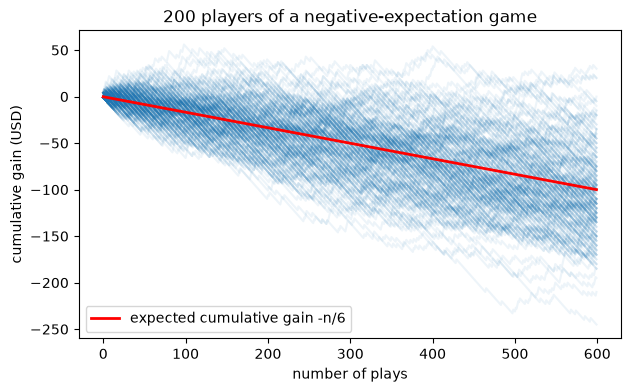

players ahead after 600 plays: 3 of 200


In [15]:
plays = 600
n_players = 200
gains = np.where(rng.integers(1, 7, size=(n_players, plays)) == 6, 4, -1).cumsum(axis=1)
plt.plot(gains.T, color="C0", alpha=0.08)
plt.plot(np.arange(1, plays + 1) * (-1/6), "r", lw=2, label="expected cumulative gain -n/6")
plt.xlabel("number of plays"); plt.ylabel("cumulative gain (USD)")
plt.title("200 players of a negative-expectation game")
plt.legend(); plt.show()
print(f"players ahead after {plays} plays: {(gains[:, -1] > 0).sum()} of {n_players}")

The column "mean X+Y" equals "E X + E Y" in every row, including the perfectly dependent pairs — that
is linearity. The *product* rule, by contrast, fails as soon as dependence enters:
$\mathbb{E}[X \cdot X] = 15.17 \neq 12.25$. In the game plot, individual players drift around, a few are
briefly ahead, but the cloud follows the red line $-n/6$; after 600 plays almost nobody is in profit.

## 7. Variance, standardisation and Chebyshev's inequality

$\operatorname{Var}(X) = \mathbb{E}[X^2] - \mu^2$, $\operatorname{Var}(aX + b) = a^2\operatorname{Var}(X)$, and
$\operatorname{Var}(X + Y) = \operatorname{Var}X + \operatorname{Var}Y + 2\operatorname{Cov}(X, Y)$. For the
same three pairs as above we see the covariance term at work, then we check Chebyshev's bound
$P(|X - \mu| \ge k\sigma) \le 1/k^2$ against the truth for a skewed distribution.

In [16]:
var_X = E_X2 - E_X ** 2
print(f"die: Var(X) = 91/6 - 3.5^2 = {var_X:.4f}   sd = {np.sqrt(var_X):.4f}")
print(f"scaling: Var(2X + 10) exact = 4 Var(X) = {4*var_X:.4f}   simulated = {np.var(2*X + 10):.4f}")

print(f"\n{'pair':28s} {'Var X':>7s} {'Var Y':>7s} {'Var(X+Y)':>9s} {'VarX+VarY':>10s} {'2 Cov':>7s}")
for name, Y in pairs.items():
    cov = np.mean((X - X.mean()) * (Y - Y.mean()))
    print(f"{name:28s} {X.var():7.3f} {Y.var():7.3f} {(X + Y).var():9.3f} {X.var() + Y.var():10.3f} {2*cov:7.3f}")

# standardisation
Z = (X - E_X) / np.sqrt(var_X)
print(f"\nz-scores of the die: mean {Z.mean():.4f}, var {Z.var():.4f};  a six has z = {(6 - E_X)/np.sqrt(var_X):.3f}")

# averages: Var(mean of n) = sigma^2 / n   (the samples are kept for the histogram further down)
avg_of = {}
for m in (1, 4, 16, 64):
    avg_of[m] = rng.integers(1, 7, size=(50_000, m)).mean(axis=1)
    print(f"average of {m:2d} dice: sd = {avg_of[m].std():.4f}   sigma/sqrt(n) = {np.sqrt(var_X/m):.4f}")

die: Var(X) = 91/6 - 3.5^2 = 2.9167   sd = 1.7078
scaling: Var(2X + 10) exact = 4 Var(X) = 11.6667   simulated = 11.6722

pair                           Var X   Var Y  Var(X+Y)  VarX+VarY   2 Cov
independent second die         2.918   2.922     5.830      5.840  -0.010
Y = 7 - X (dependent)          2.918   2.918     0.000      5.836  -5.836
Y = X (dependent)              2.918   2.918    11.672      5.836   5.836

z-scores of the die: mean 0.0003, var 1.0005;  a six has z = 1.464
average of  1 dice: sd = 1.7078   sigma/sqrt(n) = 1.7078
average of  4 dice: sd = 0.8534   sigma/sqrt(n) = 0.8539
average of 16 dice: sd = 0.4251   sigma/sqrt(n) = 0.4270
average of 64 dice: sd = 0.2136   sigma/sqrt(n) = 0.2135


In the variance table the first row (independent dice) has a covariance near 0 and the variances add;
the second row has $\operatorname{Cov} = -\operatorname{Var}X$ and $X + Y = 7$ has *zero* variance; the
third has $\operatorname{Var}(2X) = 4\operatorname{Var}X$, twice what naive addition would give. The next
figure shows where these numbers come from: the joint distribution of each pair (top) and the
distribution of $X + Y$ it produces (bottom).

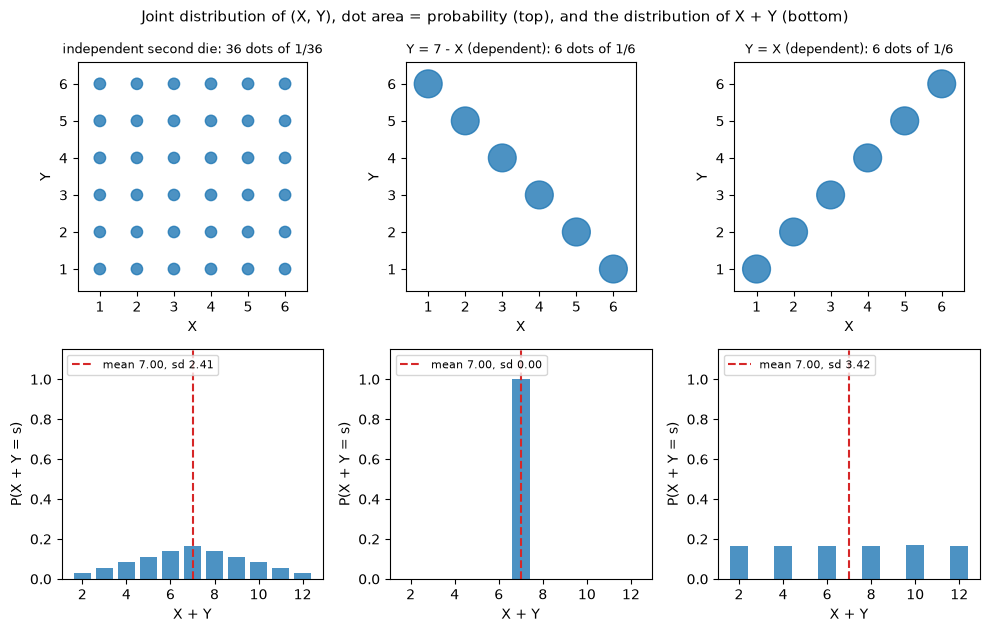

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6.4))
cells = np.arange(1, 7)
s_vals = np.arange(2, 13)
dots = {"independent second die": "36 dots of 1/36", "Y = 7 - X (dependent)": "6 dots of 1/6",
        "Y = X (dependent)": "6 dots of 1/6"}
for j, (name, Y) in enumerate(pairs.items()):
    joint = np.array([[np.mean((X == a) & (Y == b)) for b in cells] for a in cells])   # joint[a-1, b-1]
    A, B = np.meshgrid(cells, cells, indexing="ij")
    ax = axes[0, j]
    ax.scatter(A.ravel(), B.ravel(), s=2400 * joint.ravel(), color="C0", alpha=0.8)
    ax.set_xlim(0.4, 6.6); ax.set_ylim(0.4, 6.6); ax.set_aspect("equal")
    ax.set_xticks(cells); ax.set_yticks(cells)
    ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_title(f"{name}: {dots[name]}", fontsize=9)
    S = X + Y
    pmf_s = np.array([np.mean(S == s) for s in s_vals])
    ax = axes[1, j]
    ax.bar(s_vals, pmf_s, color="C0", alpha=0.8)
    ax.axvline(S.mean(), color="C3", ls="--", label=f"mean {S.mean():.2f}, sd {S.std():.2f}")
    ax.set_ylim(0, 1.15); ax.set_xticks(range(2, 13, 2))
    ax.set_xlabel("X + Y"); ax.set_ylabel("P(X + Y = s)"); ax.legend(fontsize=8, loc="upper left")
fig.suptitle("Joint distribution of (X, Y), dot area = probability (top), and the distribution of X + Y (bottom)",
             fontsize=11)
plt.tight_layout(); plt.show()

**Notice that** the three joint distributions look nothing alike — 36 small dots of $1/36$ each, six
large dots on the anti-diagonal, six on the diagonal — yet every lower panel has its mean at 7: that is
linearity of expectation. What the dependence changes is the *spread* of $X + Y$: a triangle from 2 to
12 (sd $\sqrt{35/6} \approx 2.4$) when the variances simply add, a single spike at 7 (sd $0$) when the
negative covariance cancels them, and six bars on the even numbers 2 to 12 (sd $3.42 = 2 \times 1.71$) when the positive
covariance doubles the sum.

The last block of the variance cell averaged $n$ dice; here are those averages as histograms.

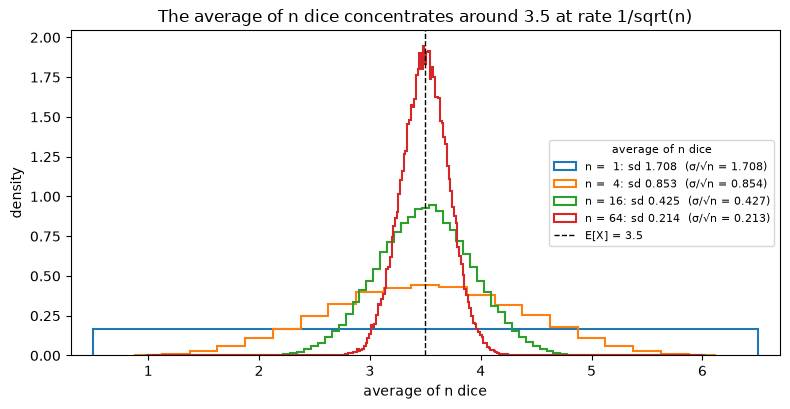

In [18]:
plt.figure(figsize=(8, 4.2))
for m in (1, 4, 16, 64):
    bins = np.arange(1 - 1 / (2 * m), 6 + 1 / m, 1 / m)   # one bin per possible value k/m of the average
    plt.hist(avg_of[m], bins=bins, density=True, histtype="step", lw=1.5,
             label=f"n = {m:2d}: sd {avg_of[m].std():.3f}  (σ/√n = {np.sqrt(var_X / m):.3f})")
plt.axvline(3.5, color="k", ls="--", lw=1, label="E[X] = 3.5")
plt.xlim(0.3, 6.7)
plt.xlabel("average of n dice"); plt.ylabel("density")
plt.title("The average of n dice concentrates around 3.5 at rate 1/sqrt(n)")
plt.legend(title="average of n dice", fontsize=8, title_fontsize=8, loc="center right"); plt.tight_layout(); plt.show()

**Notice that** every fourfold increase in the number of dice halves the width of the distribution of
the average — the standard deviation falls exactly like $\sigma/\sqrt{n}$ — and that its shape changes
on the way: flat for one die, a bell for 16 or 64. The narrowing is Chebyshev-type concentration, which
we test next; the bell shape is the central limit theorem of Module 8.

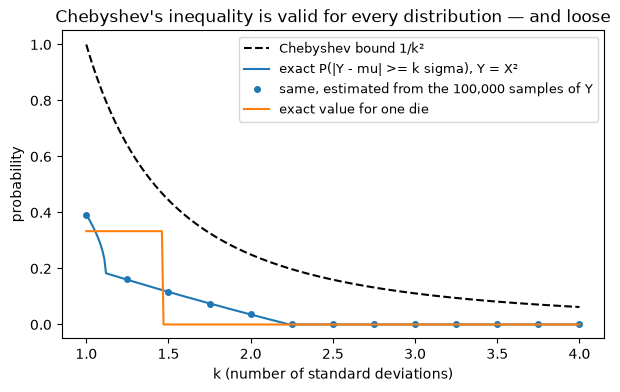

k = 1.5: bound 0.444   Y = X^2: exact 0.1165, simulated 0.1170   die: exact 0.0000
k = 2: bound 0.250   Y = X^2: exact 0.0358, simulated 0.0358   die: exact 0.0000
k = 3: bound 0.111   Y = X^2: exact 0.0000, simulated 0.0000   die: exact 0.0000


In [19]:
# Chebyshev vs truth for a skewed variable: Y = X^2 with X ~ Uniform(0,1)  (mean 1/3, var 4/45)
mu_y, sd_y = 1/3, np.sqrt(4/45)

def tail_y_exact(t):
    # P(|Y - mu| >= t) = P(Y >= mu + t) + P(Y <= mu - t), with F_Y(y) = sqrt(y) on [0, 1]
    return (1 - np.sqrt(np.clip(mu_y + t, 0, 1))) + np.sqrt(np.clip(mu_y - t, 0, 1))

def tail_die_exact(k):
    # P(|X - 3.5| >= k sigma) for one fair die: count the faces far enough from 3.5
    return np.mean(np.abs(faces - 3.5) >= k * np.sqrt(35/12))

ks = np.linspace(1, 4, 301)
ks_dots = ks[::25]
plt.plot(ks, 1 / ks**2, "k--", label="Chebyshev bound 1/k²")
plt.plot(ks, tail_y_exact(ks * sd_y), color="C0", label="exact P(|Y - mu| >= k sigma), Y = X²")
plt.plot(ks_dots, [np.mean(np.abs(y - mu_y) >= k * sd_y) for k in ks_dots], "o", color="C0", ms=4,
         label="same, estimated from the 100,000 samples of Y")
plt.plot(ks, [tail_die_exact(k) for k in ks], color="C1", label="exact value for one die")
plt.xlabel("k (number of standard deviations)"); plt.ylabel("probability")
plt.title("Chebyshev's inequality is valid for every distribution — and loose")
plt.legend(fontsize=9); plt.show()
for k in (1.5, 2, 3):
    print(f"k = {k}: bound {1/k**2:.3f}   Y = X^2: exact {tail_y_exact(k * sd_y):.4f}, "
          f"simulated {np.mean(np.abs(y - mu_y) >= k*sd_y):.4f}   die: exact {tail_die_exact(k):.4f}")

The Chebyshev plot shows the bound sitting well above both true curves — it is a guarantee, not an
estimate — and at $k = 3$ it still allows $11\%$ in the tails where both the die and $Y = X^2$ have $0\%$.

**Try it yourself:** in the Chebyshev cell, generate a heavy-tailed sample such as
`rng.standard_t(df=3, size=100_000)` and compare its tail probabilities with the bound.

## 8. Monte Carlo: estimating $\pi$ and the $1/\sqrt{n}$ law

Throw $n$ uniform points into the unit square. The fraction landing inside the quarter circle
$x^2 + y^2 \le 1$ estimates $\pi/4$. The estimate is an average of indicators, so its standard
deviation is $\sqrt{p(1-p)/n}$ with $p = \pi/4$; multiplied by 4 the error of $\hat\pi$ is about
$1.64/\sqrt{n}$. We check this by repeating the whole experiment 200 times for each $n$.

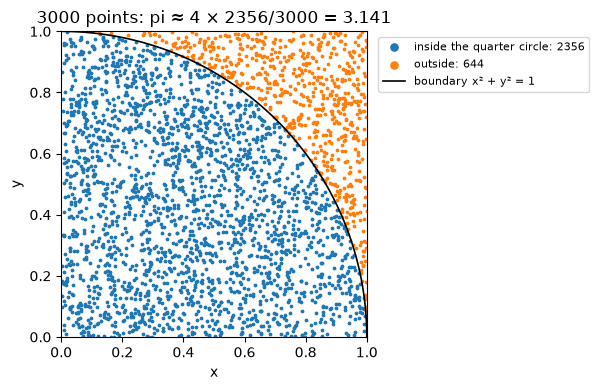

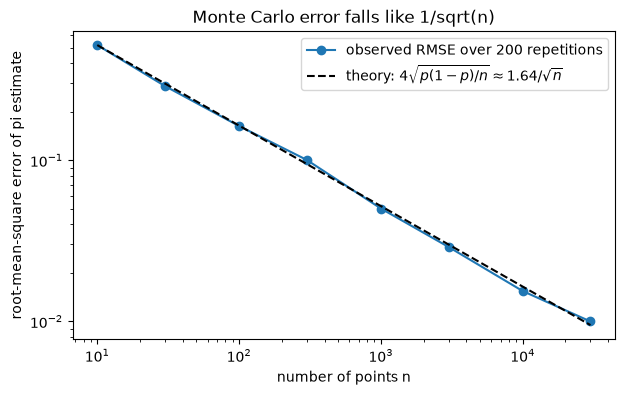

n =     10: RMSE 0.5196   theory 0.5193
n =     30: RMSE 0.2891   theory 0.2998
n =    100: RMSE 0.1632   theory 0.1642
n =    300: RMSE 0.1005   theory 0.0948
n =   1000: RMSE 0.0502   theory 0.0519
n =   3000: RMSE 0.0290   theory 0.0300
n =  10000: RMSE 0.0154   theory 0.0164
n =  30000: RMSE 0.0100   theory 0.0095


In [20]:
def estimate_pi(n, rng):
    pts = rng.random((n, 2))
    inside = (pts ** 2).sum(axis=1) <= 1.0
    return 4 * inside.mean()

pts = rng.random((3000, 2)); inside = (pts ** 2).sum(axis=1) <= 1
t = np.linspace(0, np.pi / 2, 200)
plt.figure(figsize=(6.4, 4))
plt.scatter(pts[inside, 0], pts[inside, 1], s=3, label=f"inside the quarter circle: {inside.sum()}")
plt.scatter(pts[~inside, 0], pts[~inside, 1], s=3, label=f"outside: {(~inside).sum()}")
plt.plot(np.cos(t), np.sin(t), "k-", lw=1.2, label="boundary x² + y² = 1")
plt.xlim(0, 1); plt.ylim(0, 1); plt.gca().set_aspect("equal"); plt.xlabel("x"); plt.ylabel("y")
plt.title(f"3000 points: pi ≈ 4 × {inside.sum()}/3000 = {4*inside.mean():.3f}")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8, markerscale=3)
plt.tight_layout(); plt.show()

ns = np.array([10, 30, 100, 300, 1_000, 3_000, 10_000, 30_000])
reps = 200
rmse = []
for n_pts in ns:
    ests = np.array([estimate_pi(n_pts, rng) for _ in range(reps)])
    rmse.append(np.sqrt(np.mean((ests - np.pi) ** 2)))
rmse = np.array(rmse)
theory = 4 * np.sqrt((np.pi/4) * (1 - np.pi/4) / ns)

plt.loglog(ns, rmse, "o-", label="observed RMSE over 200 repetitions")
plt.loglog(ns, theory, "k--", label=r"theory: $4\sqrt{p(1-p)/n} \approx 1.64/\sqrt{n}$")
plt.xlabel("number of points n"); plt.ylabel("root-mean-square error of pi estimate")
plt.title("Monte Carlo error falls like 1/sqrt(n)"); plt.legend(); plt.show()
for n_pts, r, t in zip(ns, rmse, theory):
    print(f"n = {n_pts:>6d}: RMSE {r:.4f}   theory {t:.4f}")

On log–log axes the error is a straight line of slope $-1/2$: every factor of 100 in $n$ buys one
decimal digit. This is the same $\sigma/\sqrt{n}$ you saw for averages of dice, and it is the reason
Monte Carlo is cheap for two digits and ruinously expensive for six. The birthday problem works the
same way: we simulate 10,000 groups of 23 people and compare the share of groups with a shared birthday
with the exact product formula $1 - \prod_{i=0}^{22} \frac{365 - i}{365}$ of the guide.

In [21]:
n_people, n_groups = 23, 10_000
p_shared_exact = 1 - np.prod((365 - np.arange(n_people)) / 365)      # 1 - P(all birthdays different)
bdays = np.sort(rng.integers(0, 365, size=(n_groups, n_people)), axis=1)
shared = (np.diff(bdays, axis=1) == 0).any(axis=1)                   # equal neighbours after sorting
se_bday = np.sqrt(p_shared_exact * (1 - p_shared_exact) / n_groups)
print(f"exact P(at least one shared birthday among {n_people}) = {p_shared_exact:.4f}")
print(f"simulated with {n_groups:,} groups                      = {shared.mean():.4f}   "
      f"(standard error {se_bday:.4f}, so typically within {p_shared_exact - 2*se_bday:.3f}-{p_shared_exact + 2*se_bday:.3f})")

exact P(at least one shared birthday among 23) = 0.5073
simulated with 10,000 groups                      = 0.5009   (standard error 0.0050, so typically within 0.497-0.517)


The simulated value lands inside the two-standard-error window around $0.507$, just as the $1/\sqrt{n}$
law predicts. Exercise 5 turns this into reusable functions, uses twice as many groups and asks for the
smallest group in which a shared birthday is 99% certain.

## 9. A naive Bayes spam filter, by hand

For a message with words $w_1, \dots, w_m$:

$$\hat c = \arg\max_c \Big[\log P(c) + \sum_j \log \hat P(w_j \mid c)\Big], \qquad
\hat P(w \mid c) = \frac{\text{count}(w, c) + 1}{\text{tokens in } c + V}.$$

We build a 12-message corpus, count words per class, apply Laplace smoothing, and classify new
messages in log space. The per-word log-likelihood ratio $\log \frac{P(w \mid \text{spam})}{P(w \mid \text{ham})}$
tells us which words drive each decision. Finally we check against `sklearn.naive_bayes.MultinomialNB`.

In [22]:
from collections import Counter

corpus = [
    ("free money now click here",          "spam"),
    ("win a free prize now",                "spam"),
    ("claim your free offer today",         "spam"),
    ("cheap meds money back guarantee",     "spam"),
    ("you win money click now",             "spam"),
    ("exclusive offer limited time click",  "spam"),
    ("team meeting moved to tomorrow",      "ham"),
    ("can you review the project report",   "ham"),
    ("lunch today at noon",                 "ham"),
    ("notes from the meeting attached",     "ham"),
    ("project deadline is friday",          "ham"),
    ("call me back when you are free",      "ham"),
]
classes = ("spam", "ham")
docs = {c: [m.split() for m, lab in corpus if lab == c] for c in classes}
counts = {c: Counter(w for d in docs[c] for w in d) for c in classes}
vocab = sorted(set(w for d in docs["spam"] + docs["ham"] for w in d))
V = len(vocab)
n_tokens = {c: sum(counts[c].values()) for c in classes}
log_prior = {c: np.log(len(docs[c]) / len(corpus)) for c in classes}
print(f"vocabulary size V = {V};  tokens: {n_tokens};  log priors: { {c: round(v, 3) for c, v in log_prior.items()} }")

def log_word_prob(word, c, alpha=1.0):
    # Laplace-smoothed estimate of P(word | class), in log space
    return np.log((counts[c][word] + alpha) / (n_tokens[c] + alpha * V))

def classify(message, alpha=1.0, verbose=False):
    words = [w for w in message.split() if w in vocab]      # ignore words never seen in training
    scores = {c: log_prior[c] + sum(log_word_prob(w, c, alpha) for w in words) for c in classes}
    # normalise to a posterior with the log-sum-exp trick
    m = max(scores.values())
    post = {c: np.exp(s - m) / sum(np.exp(v - m) for v in scores.values()) for c, s in scores.items()}
    if verbose:
        print(f"'{message}'")
        for w in words:
            print(f"    {w:10s} log P(w|spam) = {log_word_prob(w, 'spam', alpha):7.3f}   log P(w|ham) = {log_word_prob(w, 'ham', alpha):7.3f}"
                  f"   log-likelihood ratio = {log_word_prob(w, 'spam', alpha) - log_word_prob(w, 'ham', alpha):+.3f}")
        print(f"    log scores: spam {scores['spam']:.3f}, ham {scores['ham']:.3f}   ->  P(spam | message) = {post['spam']:.3f}")
    return max(scores, key=scores.get), post["spam"]

for msg in ["free money offer", "meeting about the project report", "click to win a prize", "free lunch at the meeting"]:
    classify(msg, verbose=True)

vocabulary size V = 43;  tokens: {'spam': 30, 'ham': 31};  log priors: {'spam': np.float64(-0.693), 'ham': np.float64(-0.693)}
'free money offer'
    free       log P(w|spam) =  -2.904   log P(w|ham) =  -3.611   log-likelihood ratio = +0.707
    money      log P(w|spam) =  -2.904   log P(w|ham) =  -4.304   log-likelihood ratio = +1.400
    offer      log P(w|spam) =  -3.192   log P(w|ham) =  -4.304   log-likelihood ratio = +1.112
    log scores: spam -9.693, ham -12.912   ->  P(spam | message) = 0.962
'meeting about the project report'
    meeting    log P(w|spam) =  -4.290   log P(w|ham) =  -3.205   log-likelihood ratio = -1.085
    the        log P(w|spam) =  -4.290   log P(w|ham) =  -3.205   log-likelihood ratio = -1.085
    project    log P(w|spam) =  -4.290   log P(w|ham) =  -3.205   log-likelihood ratio = -1.085
    report     log P(w|spam) =  -4.290   log P(w|ham) =  -3.611   log-likelihood ratio = -0.680
    log scores: spam -17.855, ham -13.920   ->  P(spam | message) = 0.019


The printout is easier to read as a running total. Start from the prior log-odds
$\log\frac{P(\text{spam})}{P(\text{ham})}$ and add each word's log-likelihood ratio in turn; the sign at
the end is the decision.

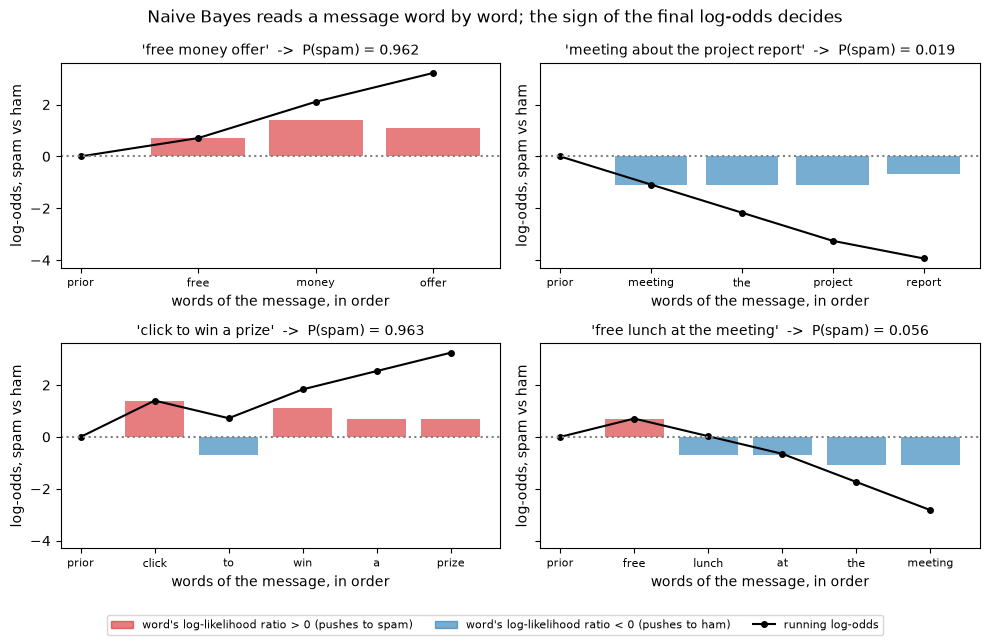

In [23]:
from matplotlib.lines import Line2D

trace_msgs = ["free money offer", "meeting about the project report", "click to win a prize", "free lunch at the meeting"]
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharey=True)
for ax, msg in zip(axes.ravel(), trace_msgs):
    words = [w for w in msg.split() if w in vocab]
    step = np.array([log_word_prob(w, "spam") - log_word_prob(w, "ham") for w in words])
    start = log_prior["spam"] - log_prior["ham"]                     # 0 here: 6 spam and 6 ham messages
    running = start + np.cumsum(step)
    pos = np.arange(1, len(words) + 1)
    ax.bar(pos, step, color=["C3" if v > 0 else "C0" for v in step], alpha=0.6)
    ax.plot(np.r_[0, pos], np.r_[start, running], "ko-", ms=4)
    ax.axhline(0, color="gray", ls=":")
    ax.set_xticks(np.r_[0, pos]); ax.set_xticklabels(["prior"] + words, fontsize=8)
    ax.set_xlabel("words of the message, in order"); ax.set_ylabel("log-odds, spam vs ham")
    ax.set_title(f"'{msg}'  ->  P(spam) = {classify(msg)[1]:.3f}", fontsize=10)
handles = [Patch(color="C3", alpha=0.6, label="word's log-likelihood ratio > 0 (pushes to spam)"),
           Patch(color="C0", alpha=0.6, label="word's log-likelihood ratio < 0 (pushes to ham)"),
           Line2D([], [], color="k", marker="o", ms=4, label="running log-odds")]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=8)
fig.suptitle("Naive Bayes reads a message word by word; the sign of the final log-odds decides")
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

**Notice that** the prior contributes nothing here (six spam and six ham training messages, so
$\log 1 = 0$), and that each word simply moves the running total up (red) or down (blue). "free money
offer" climbs with every word; "free lunch at the meeting" starts with a step towards spam, but the
four ham-leaning words that follow ("lunch", "at", "the", "meeting") pull it well below zero, so the one
spam word is outvoted. The same additive bookkeeping was at work in the sequential diagnostic tests of
Section 4 — each test result there, each word here, adds its log-likelihood ratio. Words never seen in
training, such as "about", are skipped, exactly as in `classify`, so they get no bar.

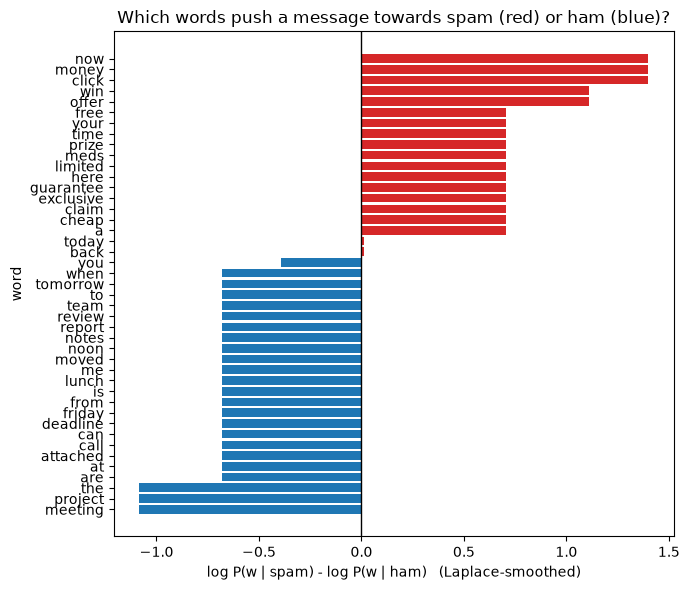

unsmoothed log score for 'win free money at the meeting' under spam:   -inf   vetoed by ['at', 'the', 'meeting']
unsmoothed log score for 'win free money at the meeting' under ham :   -inf   vetoed by ['win', 'money']
-> every class containing one unseen word scores -inf, so the strong evidence in the other words is thrown away;
   with Laplace smoothing the same message gets P(spam) = 0.591


In [24]:
# the words that carry the most weight, as log-likelihood ratios
llr = {w: log_word_prob(w, "spam") - log_word_prob(w, "ham") for w in vocab}
top = sorted(llr.items(), key=lambda kv: kv[1])
words_sorted = [w for w, _ in top]; vals = [v for _, v in top]
plt.figure(figsize=(7, 6))
plt.barh(words_sorted, vals, color=["C0" if v < 0 else "C3" for v in vals])
plt.axvline(0, color="k", lw=1)
plt.xlabel("log P(w | spam) - log P(w | ham)   (Laplace-smoothed)"); plt.ylabel("word")
plt.title("Which words push a message towards spam (red) or ham (blue)?")
plt.tight_layout(); plt.show()

# without smoothing a single unseen word vetoes a class
def unsmoothed_log_prob(word, c):
    p = counts[c][word] / n_tokens[c]
    return np.log(p) if p > 0 else -np.inf

msg = "win free money at the meeting".split()
for c in classes:
    vetoes = [w for w in msg if w in vocab and counts[c][w] == 0]
    score = log_prior[c] + sum(unsmoothed_log_prob(w, c) for w in msg if w in vocab)
    print(f"unsmoothed log score for '{' '.join(msg)}' under {c:4s}: {score:>6}   vetoed by {vetoes}")
print("-> every class containing one unseen word scores -inf, so the strong evidence in the other words is thrown away;")
print("   with Laplace smoothing the same message gets P(spam) =", f"{classify(' '.join(msg))[1]:.3f}")

In [25]:
# verify against scikit-learn's MultinomialNB (alpha=1 is Laplace smoothing)
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

vec = CountVectorizer(vocabulary=vocab, token_pattern=r"(?u)\b\w+\b")
X_train = vec.transform([m for m, _ in corpus])
y_train = [lab for _, lab in corpus]
clf = MultinomialNB(alpha=1.0).fit(X_train, y_train)

tests = ["free money offer", "meeting about the project report", "click to win a prize", "free lunch at the meeting"]
spam_col = list(clf.classes_).index("spam")
sk_post = clf.predict_proba(vec.transform(tests))[:, spam_col]
for msg, p_sk in zip(tests, sk_post):
    label, p_hand = classify(msg)
    print(f"{msg:35s} hand: P(spam) = {p_hand:.4f}   sklearn: {p_sk:.4f}   agree: {abs(p_hand - p_sk) < 1e-9}")

free money offer                    hand: P(spam) = 0.9615   sklearn: 0.9615   agree: True
meeting about the project report    hand: P(spam) = 0.0192   sklearn: 0.0192   agree: True
click to win a prize                hand: P(spam) = 0.9625   sklearn: 0.9625   agree: True
free lunch at the meeting           hand: P(spam) = 0.0561   sklearn: 0.0561   agree: True


Hand computation and `MultinomialNB` agree to machine precision, because they *are* the same
formula: class log-priors from class frequencies, smoothed word log-probabilities from counts. The
bar chart is the model's entire knowledge — a single log-likelihood ratio per word — which is why
naive Bayes is so easy to interpret and so easy to fool (repeat "meeting" ten times in a spam message).
"free lunch at the meeting" shows the model weighing evidence: "free" argues for spam, "lunch" and
"meeting" for ham, and the sum decides.

**Try it yourself:** set `alpha=0.1` in `classify` — does the posterior for the ambiguous message
become more or less extreme? Then add a new ham message containing the word "free" to the corpus
and watch its log-likelihood ratio move.

## Summary

- Relative frequencies converge to probabilities at rate $1/\sqrt{n}$ — the same rate that governs every Monte Carlo estimate.
- With equally likely outcomes, probability is counting; complements, inclusion–exclusion and the union bound follow from the three axioms.
- Conditioning is filtering the sample space; the law of total probability sums over a partition; dependence shows up as $P(A \mid B) \ne P(A)$.
- Bayes' theorem inverts conditionals; at low prevalence the PPV is driven by specificity, and sequential evidence multiplies likelihood ratios in odds form.
- PMFs sum to 1, PDFs integrate to 1 and may exceed 1, CDFs give probabilities of intervals, quantile functions invert them; $f_Y = f_X(g^{-1})\,|(g^{-1})'|$ for monotone transformations.
- Expectation is linear for *all* random variables; $\mathbb{E}[g(X)] \ne g(\mathbb{E}[X])$ and $\mathbb{E}[XY] \ne \mathbb{E}[X]\mathbb{E}[Y]$ in general.
- Variances add only up to a covariance term; standardisation gives $z$-scores; Chebyshev bounds tails for every distribution with finite, non-zero variance.
- Naive Bayes is Bayes' theorem plus conditional independence plus Laplace smoothing, computed in log space — and it matches `MultinomialNB` exactly.

**Next:** open `exercises.ipynb` and work through the self-checked problems; the solutions notebook has reference implementations.